In [54]:
import pandas as pd
import numpy as np
import pandas as pd
import astropy.constants as const
from matplotlib import pyplot as plt
import time

In [ ]:


def generate_perpendicular_transitions(Jmax):
    """
    Generate all allowed perpendicular rotational transitions for symmetric top molecule.
    
    Calculates quantum mechanical transitions for molecules like NH₃ or CH₃Cl
    when they absorb/emit light. Used to predict spectral lines in IR/microwave spectra.
    
    Parameters
    ----------
    Jmax : int
        Maximum rotational quantum number. Typical values: 20-50 for room temperature.
    
    Returns
    -------
    pd.DataFrame
        Table with columns:
        - ground_J, excited_J : Initial and final rotational states
        - ground_K, excited_K : Projection quantum numbers (0 ≤ K ≤ J)
        - delta_J, delta_K : Changes in quantum numbers
        - label : Branch type (pP, rP, pQ, rQ, pR, rR)
    
    Notes
    -----
    Selection rules for perpendicular transitions:
    - ΔJ = 0, ±1 (change in rotational quantum number)
    - ΔK = ±1 (change in projection quantum number)
    
    Branch labels:
    - P (ΔJ=-1), Q (ΔJ=0), R (ΔJ=+1)
    - p (ΔK=-1), r (ΔK=+1)
    
    Examples
    --------
    >>> df = generate_perpendicular_transitions(Jmax=5)
    >>> print(f"Total transitions: {len(df)}")
    >>> print(df['label'].value_counts())
    >>> q_branch = df[df['delta_J'] == 0]  # Get Q-branch only
    """
    
    transitions = []
    
    # Define branch rules: (delta_J, delta_K, branch_name)
    branch_rules = [
        (-1, -1, 'pP'),  # P branch, K decreasing
        (-1, +1, 'rP'),  # P branch, K increasing
        (0,  -1, 'pQ'),  # Q branch, K decreasing
        (0,  +1, 'rQ'),  # Q branch, K increasing
        (+1, -1, 'pR'),  # R branch, K decreasing
        (+1, +1, 'rR'),  # R branch, K increasing
    ]
    
    # Generate all valid transitions
    for delta_J, delta_K, label in branch_rules:
        for J in range(Jmax + 1):
            J_prime = J + delta_J
            
            # Check if J' is valid
            if J_prime < 0 or J_prime > Jmax:
                continue
            
            # For each valid J, iterate over allowed K values
            for K in range(J + 1):  # K ranges from 0 to J
                K_prime = K + delta_K
                
                # Check if K' is valid (must be between 0 and J')
                if K_prime < 0 or K_prime > J_prime:
                    continue
                
                transitions.append({
                    'ground_J': J,
                    'excited_J': J_prime,
                    'ground_K': K,
                    'excited_K': K_prime,
                    'delta_J': delta_J,
                    'delta_K': delta_K,
                    'label': label
                })
    
    return pd.DataFrame(transitions)

In [57]:
import numpy as np

def calculate_rotational_constants(ground_B, delta_B_percent, B_by_C = 2):

    """
    Calculate rotational constant B and C for ground and excited states.

    For oblate tops, A = B = 2C 
    
    Assumes and same percent change for both constants upon excitation.
    
    Parameters
    ----------
    ground_B : float
        rotational constant B in ground state (cm⁻¹)
    delta_B_percent : float
        Percent change in rotational constant B (%)
    B_by_C : float
        ratio of rotational constants (B/C)
    
    Returns
    -------
    tuple
        (ground_B, ground_C, excited_B, excited_C) all in cm⁻¹

    """

    ground_C = ground_B / B_by_C
    excited_B = ground_B * (1 + delta_B_percent / 100)
    excited_C = ground_C * (1 + delta_B_percent / 100)
    
    return ground_B, ground_C, excited_B, excited_C

# print(calculate_rotational_constants(ground_B=3e-3, delta_B_percent=0.1, B_by_C=2))


In [184]:
def calc_transwno(linelist, ground_B, delta_B, zeta, origin):
    """
    Calculate energies and wavenumbers for all transitions.
    
    Parameters
    ----------
    linelist : pd.DataFrame
        Transition table with columns: ground_J, ground_K, excited_J, excited_K, delta_K 
    ground_B : float
        Ground state rotational constant B (cm⁻¹)
    delta_B : float
        Percent change in B upon excitation (%)
    zeta : float
        Coriolis coupling constant (dimensionless)
    origin : float
        Vibrational band origin (cm⁻¹)
    
    Returns
    -------
    pd.DataFrame
        Linelist with added columns: ground_E, excited_E, wavenumber
    """
    # Calculate rotational constants once
    ground_B, ground_C, excited_B, excited_C = calculate_rotational_constants(ground_B, delta_B)
    
    # Pre-compute constant terms
    ground_BC_diff = ground_C - ground_B
    excited_BC_diff = excited_C - excited_B
    coriolis_factor = -2 * excited_C * zeta
    coriolis_offset = excited_C **2
    
    # Vectorized calculations using pandas operations (faster than .values)
    # Ground state energies
    ground_E = (ground_B * linelist['ground_J'] * (linelist['ground_J'] + 1) + 
                ground_BC_diff * linelist['ground_K']**2)
    
    # Excited state energies
    excited_E = (excited_B * linelist['excited_J'] * (linelist['excited_J'] + 1) + 
                 excited_BC_diff * linelist['excited_K']**2 +
                 coriolis_offset)
    
    # Coriolis term with sign based on delta_K
    # Use numpy.where for vectorized conditional
    coriolis_term = np.where(linelist['delta_K'] == -1, 
                             -coriolis_factor * linelist['excited_K'],
                             coriolis_factor * linelist['excited_K'])
    excited_E += coriolis_term
    
    # Assign results (single copy, no intermediate arrays)
    return linelist.assign(
        ground_E=ground_E,
        excited_E=excited_E,
        wavenumber=origin + excited_E - ground_E
    )




In [ ]:
import numpy as np

def calc_honl_london_factors(linelist):
    """
    Add Hönl-London factors to the linelist.
    
    These factors represent the relative transition strengths arising
    from quantum mechanical selection rules for symmetric top molecules.
    
    Parameters
    ----------
    linelist : pd.DataFrame
        Transition table with columns: ground_J, ground_K, delta_J, delta_K
    
    Returns
    -------
    pd.DataFrame
        Linelist with added column: HL_factor
    
    Notes
    -----
    Branch formulas from Herzberg, "Molecular Spectra and Molecular Structure II":
    - pP (ΔJ=-1, ΔK=-1): [(J-1+K)(J+K)] / [J(2J+1)]
    - rP (ΔJ=-1, ΔK=+1): [(J-1-K)(J-K)] / [J(2J+1)]
    - pQ (ΔJ=0,  ΔK=-1): [(J+1-K)(J+K)] / [J(J+1)]
    - rQ (ΔJ=0,  ΔK=+1): [(J+1+K)(J-K)] / [J(J+1)]
    - pR (ΔJ=+1, ΔK=-1): [(J+2-K)(J+1-K)] / [(J+1)(2J+1)]
    - rR (ΔJ=+1, ΔK=+1): [(J+2+K)(J+1+K)] / [(J+1)(2J+1)]
    
    Examples
    --------
    >>> linelist = add_honl_london_factors(linelist)
    >>> print(linelist[['label', 'ground_J', 'ground_K', 'HL_factor']].head())
    """
    linelist = linelist.copy()
    
    # Extract quantum numbers as arrays
    J = linelist['ground_J'].values
    K = linelist['ground_K'].values
    delta_J = linelist['delta_J'].values
    delta_K = linelist['delta_K'].values
    
    # Initialize array for Hönl-London factors
    HL_factors = np.zeros(len(J))
    
    # P-branch (ΔJ = -1)
    mask_pP = (delta_J == -1) & (delta_K == -1)
    HL_factors[mask_pP] = ((J[mask_pP] - 1 + K[mask_pP]) * (J[mask_pP] + K[mask_pP])) / \
                          (J[mask_pP] * (2 * J[mask_pP] + 1))
    
    mask_rP = (delta_J == -1) & (delta_K == 1)
    HL_factors[mask_rP] = ((J[mask_rP] - 1 - K[mask_rP]) * (J[mask_rP] - K[mask_rP])) / \
                          (J[mask_rP] * (2 * J[mask_rP] + 1))
    
    # Q-branch (ΔJ = 0)
    mask_pQ = (delta_J == 0) & (delta_K == -1)
    HL_factors[mask_pQ] = ((J[mask_pQ] + 1 - K[mask_pQ]) * (J[mask_pQ] + K[mask_pQ])) / \
                          (J[mask_pQ] * (J[mask_pQ] + 1))
    
    mask_rQ = (delta_J == 0) & (delta_K == 1)
    HL_factors[mask_rQ] = ((J[mask_rQ] + 1 + K[mask_rQ]) * (J[mask_rQ] - K[mask_rQ])) / \
                          (J[mask_rQ] * (J[mask_rQ] + 1))
    
    # R-branch (ΔJ = +1)
    mask_pR = (delta_J == 1) & (delta_K == -1)
    HL_factors[mask_pR] = ((J[mask_pR] + 2 - K[mask_pR]) * (J[mask_pR] + 1 - K[mask_pR])) / \
                          ((J[mask_pR] + 1) * (2 * J[mask_pR] + 1))
    
    mask_rR = (delta_J == 1) & (delta_K == 1)
    HL_factors[mask_rR] = ((J[mask_rR] + 2 + K[mask_rR]) * (J[mask_rR] + 1 + K[mask_rR])) / \
                          ((J[mask_rR] + 1) * (2 * J[mask_rR] + 1))
    
    # Add to linelist
    linelist['HL_factor'] = HL_factors
    
    return linelist




      ground_J  excited_J  ground_K  excited_K  delta_J  delta_K label  \
0            1          0         1          0       -1       -1    pP   
1            2          1         1          0       -1       -1    pP   
2            2          1         2          1       -1       -1    pP   
3            3          2         1          0       -1       -1    pP   
4            3          2         2          1       -1       -1    pP   
...        ...        ...       ...        ...      ...      ...   ...   
1215        19         20        15         16        1        1    rR   
1216        19         20        16         17        1        1    rR   
1217        19         20        17         18        1        1    rR   
1218        19         20        18         19        1        1    rR   
1219        19         20        19         20        1        1    rR   

      ground_E   excited_E  wavenumber  HL_factor  
0         15.0     4.60275   989.60275   0.666667  
1      

In [ ]:
import numpy as np
from astropy import constants as const

def add_boltzmann_factors_and_intensities(linelist, T):
    """
    Add Boltzmann population factors and calculate line intensities.
    
    The Boltzmann factor accounts for thermal population distribution
    of rotational states at temperature T.
    
    Parameters
    ----------
    linelist : pd.DataFrame
        Transition table with columns: ground_J, ground_K, ground_E, HL_factor
    T : float
        Temperature (Kelvin)
    
    Returns
    -------
    pd.DataFrame
        Linelist with added columns: boltzmann_factor, intensity
    
    Notes
    -----
    Boltzmann factor formula: g × (2J+1) × exp(-E/kT)
    where g is the degeneracy:
        g = 1 for K=0 (non-degenerate)
        g = 2 for K≠0 (±K degeneracy)
    
    Intensity = Hönl-London factor × Boltzmann factor
    
    Examples
    --------
    >>> linelist = add_boltzmann_factors_and_intensities(linelist, T=300)
    >>> print(linelist[['ground_J', 'ground_K', 'boltzmann_factor', 'intensity']].head())
    """
    linelist = linelist.copy()
    
    # Physical constants (CGS units)
    h = const.h.cgs.value
    c = const.c.to('cm/s').value
    k_B = const.k_B.cgs.value
    
    # Extract quantum numbers and energies
    J = linelist['ground_J'].values
    K = linelist['ground_K'].values
    E = linelist['ground_E'].values
    
    # Calculate Boltzmann factor
    # Factor = (2J+1) × exp(-hcE/kT)
    exponent = -(h * c * E) / (k_B * T)
    factor = (2 * J + 1) * np.exp(exponent)
    
    # Apply degeneracy: K=0 has g=1, K≠0 has g=2
    degeneracy = np.where(K == 0, 2, 1)
    boltzmann_factor = degeneracy * factor
    
    linelist['boltzmann_factor'] = boltzmann_factor
    
    # Calculate total intensity
    # Intensity = Hönl-London factor × Boltzmann factor
    linelist['intensity'] = linelist['HL_factor'] * boltzmann_factor
    
    return linelist




In [181]:
def calc_stickspectrum(transitions, ground_B, delta_B, zeta, origin, T):
    linelist = calc_transwno(transitions, ground_B = ground_B, delta_B = delta_B, zeta=zeta, origin=origin)
    linelist = calc_honl_london_factors(linelist=linelist)
    linelist = add_boltzmann_factors_and_intensities(linelist=linelist, T=T)

    return linelist

In [210]:
import numpy as np
import numba as nb

@nb.njit(parallel=True)
def _gaussian_convolution_kernel(line_positions, line_intensities, grid, sigma):
    """
    Numba-optimized Gaussian convolution kernel.
    
    For each grid point, calculates the sum of Gaussian profiles
    centered at each line position.
    """
    convolved = np.zeros(len(grid))
    
    for i in range(len(grid)):
        grid_point = grid[i]
        # Sum contributions from all lines
        gaussian = np.exp(-(line_positions - grid_point)**2 / (2 * sigma**2))
        convolved[i] = np.sum(gaussian * line_intensities)
    
    return convolved


def convolve_spectrum(linelist, sigma, grid_size=1000, padding=1.0):
    """
    Convolve stick spectrum with Gaussian line profiles.
    
    Each spectral line is broadened by a Gaussian function to simulate
    instrumental broadening and natural linewidth effects.
    
    Parameters
    ----------
    linelist : pd.DataFrame
        Line list with columns: wavenumber, intensity
    sigma : float
        Gaussian width parameter (FWHM ≈ 2.355 × sigma) in cm⁻¹
    grid_size : int, optional
        Number of points in the output spectrum (default: 1000)
    padding : float, optional
        Extra range to add on each side of spectrum in cm⁻¹ (default: 1.0)
    
    Returns
    -------
    wavenumber_grid : np.ndarray
        Wavenumber axis for convolved spectrum
    convolved_intensity : np.ndarray
        Convolved intensity values
    
    Notes
    -----
    Uses Gaussian line shape: I(ν) = Σ I_i × exp[-(ν - ν_i)²/(2σ²)]
    where the sum is over all spectral lines.
    
    The convolution is accelerated using Numba JIT compilation with
    parallel execution.
    
    Examples
    --------
    >>> wn_grid, intensity = convolve_spectrum(linelist, sigma=0.1)
    >>> import matplotlib.pyplot as plt
    >>> plt.plot(wn_grid, intensity)
    >>> plt.xlabel('Wavenumber (cm⁻¹)')
    >>> plt.ylabel('Intensity')
    """
    # Extract line positions and intensities
    line_positions = linelist['wavenumber'].values
    line_intensities = linelist['intensity'].values
    
    # Create wavenumber grid
    wn_min = line_positions.min() - padding
    wn_max = line_positions.max() + padding
    wavenumber_grid = np.linspace(wn_min, wn_max, grid_size)
    
    # Perform convolution using Numba-optimized kernel
    convolved_intensity = _gaussian_convolution_kernel(
        line_positions, line_intensities, wavenumber_grid, sigma
    )
    
    return wavenumber_grid, convolved_intensity




ImportError: Numba needs NumPy 1.25 or less

In [162]:
# Generate transitions
Jmax = 1000
transitions = generate_perpendicular_transitions(Jmax=Jmax)

In [198]:
start = time.time()
# Add energies and wavenumbers
linelist_new = calc_stickspectrum(
    transitions,
    ground_B=0.0022,
    delta_B=-0.07,
    zeta=-0.29,
    origin=0, 
    T = 80
)
end = time.time()
print(end-start)



0.2918357849121094


In [209]:
grid, spec = convolve_spectrum(linelist=linelist_new, sigma=0.15)

In [206]:

from scipy.signal import fftconvolve


def convolve_spectrum_fft(linelist, sigma, grid_size=1000, padding=1.0):
    """
    Convolve stick spectrum with Gaussian profiles using FFT method.
    
    Fast O(N log N) convolution - best for dense spectra with many overlapping lines.
    Uses the convolution theorem: convolution in time = multiplication in frequency.
    
    Parameters
    ----------
    linelist : pd.DataFrame
        Line list with columns: wavenumber, intensity
    sigma : float
        Gaussian width parameter (FWHM ≈ 2.355 × sigma) in cm⁻¹
    grid_size : int, optional
        Number of points in the output spectrum (default: 1000)
        Higher values give better resolution but slower computation
    padding : float, optional
        Extra range to add on each side of spectrum in cm⁻¹ (default: 1.0)
    
    Returns
    -------
    wavenumber_grid : np.ndarray
        Wavenumber axis for convolved spectrum (evenly spaced)
    convolved_intensity : np.ndarray
        Convolved intensity values
    
    Notes
    -----
    Algorithm:
    1. Bins spectral lines onto a regular grid (stick spectrum)
    2. Creates Gaussian kernel
    3. Performs FFT convolution: FFT⁻¹[ FFT(spectrum) × FFT(kernel) ]
    
    Complexity: O(N log N) vs O(N × M) for direct convolution
    Typically 10-1000× faster for dense spectra.
    
    Binning approximation: Lines are placed at nearest grid point.
    Error decreases with finer grid (larger grid_size).
    
    Examples
    --------
    >>> wn_grid, intensity = convolve_spectrum_fft(linelist, sigma=0.1, grid_size=2000)
    >>> import matplotlib.pyplot as plt
    >>> plt.plot(wn_grid, intensity)
    >>> plt.xlabel('Wavenumber (cm⁻¹)')
    >>> plt.ylabel('Intensity')
    """
    # Extract line positions and intensities
    line_positions = linelist['wavenumber'].values
    line_intensities = linelist['intensity'].values
    
    # Create evenly-spaced wavenumber grid
    wn_min = line_positions.min() - padding
    wn_max = line_positions.max() + padding
    wavenumber_grid = np.linspace(wn_min, wn_max, grid_size)
    delta_wn = wavenumber_grid[1] - wavenumber_grid[0]
    
    # ===== STEP 1: Create stick spectrum on regular grid =====
    # Bin each line to nearest grid point
    stick_spectrum = np.zeros(grid_size)
    
    for pos, intensity in zip(line_positions, line_intensities):
        # Find nearest grid point index
        idx = np.searchsorted(wavenumber_grid, pos)
        
        # Add intensity to that grid point (handle edge cases)
        if 0 <= idx < grid_size:
            stick_spectrum[idx] += intensity
    
    # ===== STEP 2: Create Gaussian kernel =====
    # Kernel should span ~10σ to capture 99.99% of Gaussian
    kernel_half_width = int(np.ceil(5.0 * sigma / delta_wn))
    kernel_size = 2 * kernel_half_width + 1
    
    # Create x-axis for kernel (centered at zero)
    kernel_x = np.arange(-kernel_half_width, kernel_half_width + 1) * delta_wn
    
    # Gaussian function: exp(-x²/2σ²)
    kernel = np.exp(-kernel_x**2 / (2 * sigma**2))
    
    # Normalize so kernel sums to 1 (preserves total intensity)
    kernel = kernel / kernel.sum()
    
    # ===== STEP 3: FFT convolution =====
    # scipy's fftconvolve handles:
    #   - FFT(stick_spectrum)
    #   - FFT(kernel) 
    #   - Pointwise multiplication in frequency domain
    #   - Inverse FFT back to wavenumber domain
    # mode='same' returns output of same size as stick_spectrum
    convolved_intensity = fftconvolve(stick_spectrum, kernel, mode='same')
    
    return wavenumber_grid, convolved_intensity



In [208]:

start = time.time()
grid2, spec2 = convolve_spectrum_fft(linelist=linelist_new, sigma = 0.15)
end = time.time()
print(end-start)

TypeError: 'numpy.ndarray' object is not callable

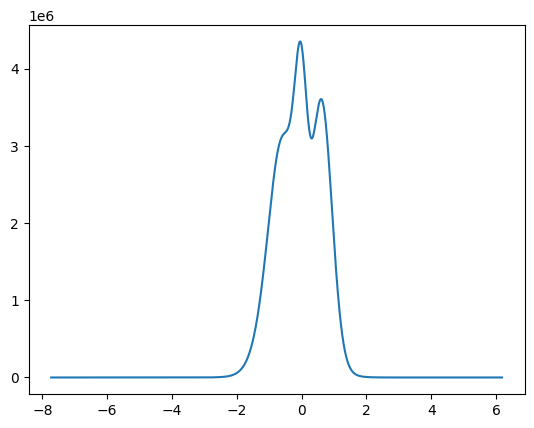

In [202]:
plt.plot(grid, int)

In [187]:
combinations = generate_perpendicular_transitions(Jmax=Jmax)

def get_rotational_spectrum(B, delta_B, zeta, T, sigma, origin):

    # start1 = timeit.default_timer()

    '''Takes in 6 parameters (molecular and environmental) 
    and calculates spectra for it. It returns linelist and model data (i.e profile after convolution)
    '''
    
   


    # rotational constants in cm-1
    ground_B = B
    ground_C = ground_B / 2
    delta_C = delta_B
    excited_B = ground_B + ((delta_B / 100) * ground_B)
    excited_C = ground_C + ((delta_C / 100) * ground_C)

    ground_Js = combinations['ground_J']
    excited_Js = combinations['excited_J']
    ground_Ks = combinations['ground_K']
    excited_Ks = combinations['excited_K']

    linelist = combinations

    delta_J = linelist['excited_J'] - linelist['ground_J']
    delta_K = linelist['excited_K'] - linelist['ground_K']

    
    '''Calculating Linelist'''

    
    ground_Es = []
    for J, K in zip(ground_Js, ground_Ks):
        ground_E = ground_B * J * (J + 1) + (ground_C - ground_B) * (K ** 2)
        ground_Es.append(ground_E)

    linelist['ground_Es'] = ground_Es

    excited_Es = []
    for J, K, del_K in zip(excited_Js, excited_Ks, delta_K):
        if del_K == -1:
            excited_E = excited_B * J * (J + 1) + (excited_C - excited_B) * (K ** 2) - (
                (-2 * excited_C * zeta)) * K + excited_C ** 2
        elif del_K == 1:
            excited_E = excited_B * J * (J + 1) + (excited_C - excited_B) * (K ** 2) + (
                (-2 * excited_C * zeta)) * K + excited_C ** 2

        excited_Es.append(excited_E)

    linelist['excited_Es'] = excited_Es

    wavenos = []
    for i in range(len(linelist.index)):
        wavenumber = origin + excited_Es[i] - ground_Es[i]
        wavenos.append(wavenumber)

    linelist['wavenos'] = wavenos
    
    
    #Compute HL_factors directly in a list comprehension
    HL_factors = [((J - 1 + K) * (J + K)) / (J * ((2 * J) + 1)) if (delta_J == -1 and delta_K == -1) else
                  ((J - 1 - K) * (J - K)) / (J * ((2 * J) + 1)) if (delta_J == -1 and delta_K == 1) else
                  (J + 1 - K) * (J + K) / (J * (J + 1)) if (delta_J == 0 and delta_K == -1) else
                  (J + 1 + K) * (J - K) / (J * (J + 1)) if (delta_J == 0 and delta_K == 1) else
                  (J + 2 - K) * (J + 1 - K) / ((J + 1) * ((2 * J) + 1)) if (delta_J == 1 and delta_K == -1) else
                  (J + 2 + K) * (J + 1 + K) / ((J + 1) * ((2 * J) + 1)) if (delta_J == 1 and delta_K == 1) else
                  None for J, K, delta_J, delta_K in zip(ground_Js, ground_Ks, delta_J, delta_K)]
    
    linelist['HL_factors'] = HL_factors
    

    
    BD_factors = []

    h = const.h.cgs.value
    c = const.c.to('cm/s').value
    k = const.k_B.cgs.value

    ground_Js_np = np.array(ground_Js)
    ground_Ks_np = np.array(ground_Ks)
    ground_Es_np = np.array(ground_Es)
    
    # Calculation of static part
    static_part = (-h * c) / (k * T)
    
    # For the condition K == 0, the equation becomes twice the general equation
    # we can pre-calculate that part
    factor = (2 * ground_Js_np + 1) * np.exp(static_part * ground_Es_np)
    
    # Wherever ground_Ks == 0, double the result
    boltzmann_equation = np.where(ground_Ks_np == 0, 2 * factor, factor)
    
    # Convert the numpy array back to list if necessary
    BD_factors = boltzmann_equation.tolist()

    linelist['BD_factors'] = BD_factors
    

    intensities = []
    for i in range(len(linelist.index)):
        strength = (HL_factors[i] * BD_factors[i])
        intensities.append(strength)

    linelist['intensities'] = intensities
    
   
    # '''Smoothening the linelist'''
    
    # smooth_wavenos = np.linspace(np.min(linelist['wavenos']) - 1, np.max(linelist['wavenos']) + 1, 1000)  # grid_size

    # Wavenos_arr = np.array(linelist['wavenos'])
    # Intenisty_arr = np.array(linelist['intensities'])


    # # @nb.njit(parallel=True)
    # def calculate_smooth_intensities(wavenos, intensities, smooth_wavenos, sigma):
    #     smooth_intensities = np.zeros(smooth_wavenos.shape)

    #     for i in range(len(smooth_wavenos)):
    #         wavepoint = smooth_wavenos[i]
    #         w_int = np.exp(-(wavenos - wavepoint) ** 2 / (2 * sigma ** 2)) * intensities
    #         smooth_intensities[i] = np.sum(w_int)

    #     return smooth_intensities

    # # call the numba function with input data
    # smooth_intensities = calculate_smooth_intensities(Wavenos_arr, Intenisty_arr, smooth_wavenos, sigma)

    # smooth_data = np.array([smooth_wavenos, smooth_intensities]).transpose()
    # #smooth_data = np.delete(smooth_data, np.where(smooth_data[:, 1] <= 0.00001 * (max(smooth_data[:, 1]))), axis=0)

    # simu_waveno = smooth_data[:, 0]
    # simu_intenisty = 1 - 0.1 * (smooth_data[:, 1] / max(smooth_data[:, 1]))
    
    # model_data = np.array([simu_waveno, simu_intenisty]).transpose()


    # for units in wavelength
    # simu_wavelength = (1/simu_waveno)*1e8
    # model_data = np.array([simu_wavelength, simu_intenisty]).transpose()
    # model_data = model_data[::-1]

    
    # end4 = timeit.default_timer()
    # print('>>>> Time taken for convolution  ' + str(end4 - start4) + '  sec')
    # print('==========')

    # endfull = timeit.default_timer()
    # print('>>>> Time taken for this profile  ' + str(endfull - startfull) + '  sec')
    print('=====')
    
    print('B = ' , ground_B)
    print('C =' , ground_C)
    print('excited_B = '  , excited_B)
    print( 'excited_C =', excited_C)
    print('delta_B = ' , delta_B)
    print('zeta = ' , zeta)
    print('T = ', T)
    print('sigma = ', sigma)
    print('origin = ' , origin) 
    print('Jmax = ',  max(combinations['excited_J']))
   
    

    return linelist #, model_data

In [188]:
linelist_old = get_rotational_spectrum(
    B=0.0022,
    delta_B=-0.07,
    zeta=-0.29,
    origin=0, 
    T = 80, 
    sigma=0.15)

=====
B =  0.0022
C = 0.0011
excited_B =  0.00219846
excited_C = 0.00109923
delta_B =  -0.07
zeta =  -0.29
T =  80
sigma =  0.15
origin =  0
Jmax =  1000


0.0 0.0
2202.2000000000003 2202.2000000000003


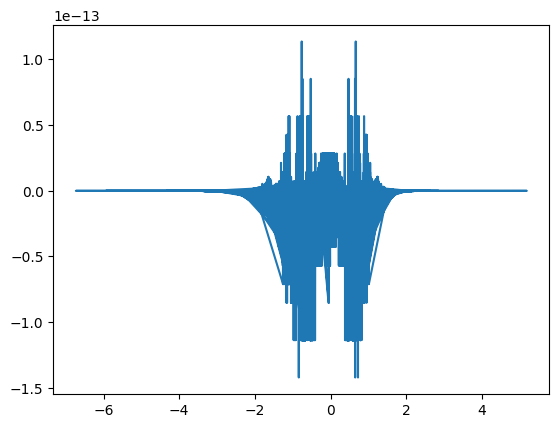

In [200]:
# plt.plot(linelist_old['wavenos'], linelist_old['intensities'])
plt.plot(linelist_new['wavenumber'], linelist_new['intensity'] - linelist_old['intensities'])
         
         #linelist_new['excited_E'] - linelist_old['excited_Es'])


print(min(linelist_new['ground_E']), min(linelist_old['ground_Es']))
print(max(linelist_new['ground_E']), max(linelist_old['ground_Es']))

In [ ]:
# start = time.time()
# # Add energies and wavenumbers
# linelist = calc_transwno(
#     transitions,
#     ground_B=0.003,
#     delta_B=2.0,
#     zeta=0.95,
#     origin=0
# )
# end = time.time()
# print(end-start)



# start = time.time()
# linelist = calc_honl_london_factors(linelist=linelist)
# end = time.time()
# print(end-start)

# start = time.time()
# linelist = add_boltzmann_factors_and_intensities(linelist=linelist, T = 100)
# end = time.time()
# print(end-start)

# # grid, intensity = convolve_spectrum(linelist=linelist, sigma = 0.1)

0.027991056442260742
0.0240631103515625
0.019527912139892578


(-300.0, 300.0)

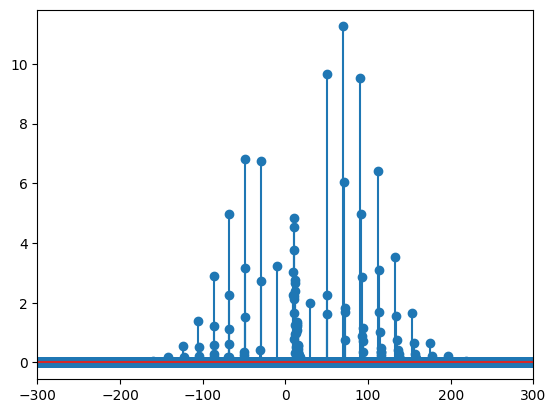

In [ ]:
# plt.stem(linelist['wavenumber'], linelist['intensity'])
# # plt.plot(grid, intensity)
# plt.xlim(-300, 300)